In [1]:
from smarties4planck.classes import (
    SkyData,
    PlanckDetectorsData,
    compute_convolved_planck_map,
)
import matplotlib.pyplot as plt
import healpy as hp
import numpy as np


In [2]:
nside = 128
lmax = 2 * nside


# Load the detector informations: blms and h-maps


In [3]:
mmax = 4 # 4 is the maximum value of mmax. Because the availabel Planck polmoments/h-maps maximum spin is 6, and the code uses h-maps of spin up to mmax+2 
det_planck_data = PlanckDetectorsData(
    detector_set="100A",  # you can refer to the list_planck() function in external_qp_planck to check the available set of detectors
    path_to_blms="inputs/gaussian_elliptical_beams/", #beams are read with healpy.read_alm 
    path_to_pol_moments="inputs/polmoments_ns0128/",  # planck h-maps are called polmoments
    path_to_rimo="inputs/RIMOs/RIMO_HFI_npipe5v16_symmetrized.fits",
    mmax_beam=mmax,
    lmax=lmax,
    blm_polar_efficiency="IMO",  # IMO or Ideal or np.array, If the blms contains polarization this does nothing, if they don't it applies the polarization efficiency when assuming copolar beams
    mapmaking_polar_efficiency="IMO",  # IMO or Ideal np.array, Polarisation efficiency assumed by the mapmaking
    ref_frame_beams="Dxx", # Pxx or Dxx,reference frame in which the beams are defined -> Dxx for the beams stored in NERSC
    ref_frame_polmoments="Pxx", # Pxx or Dxx, reference frame in which the h-maps are defined -> Pxx for the polmoments stored in NERSC
)
det_planck_data.fill_blms_dict()

det_planck_data.fill_h_maps_dict()


2026-10-15 15:25:29,609 INFO smarties4planck.external_qp_planck: Loading RIMO from inputs/RIMOs/RIMO_HFI_npipe5v16_symmetrized.fits
2026-10-15 15:25:29,623 INFO smarties4planck.external_qp_planck: maximum l in file: 256, maximum m in file: 256
2026-10-15 15:25:29,624 INFO smarties4planck.external_qp_planck: Renormalizing the beam
2026-10-15 15:25:29,624 INFO smarties4planck.core_functions: Blms in inputs/gaussian_elliptical_beams/blm_100-1a.fits contains polarization.
2026-10-15 15:25:29,633 INFO smarties4planck.external_qp_planck: maximum l in file: 256, maximum m in file: 256
2026-10-15 15:25:29,634 INFO smarties4planck.external_qp_planck: Renormalizing the beam
2026-10-15 15:25:29,635 INFO smarties4planck.core_functions: Blms in inputs/gaussian_elliptical_beams/blm_100-1b.fits contains polarization.
2026-10-15 15:25:29,641 INFO smarties4planck.external_qp_planck: maximum l in file: 256, maximum m in file: 256
2026-10-15 15:25:29,642 INFO smarties4planck.external_qp_planck: Renormali

In [4]:
det_planck_data.h_maps_dict


{np.int64(0): array([[0.20197785+0.j, 0.20584731+0.j, 0.20536436+0.j, ...,
         0.21138775+0.j, 0.20864142+0.j, 0.20467584+0.j],
        [0.20197785+0.j, 0.20584731+0.j, 0.20536436+0.j, ...,
         0.21138775+0.j, 0.20864142+0.j, 0.20467584+0.j],
        [0.29802215+0.j, 0.29415268+0.j, 0.29463562+0.j, ...,
         0.28861225+0.j, 0.29135856+0.j, 0.29532415+0.j],
        [0.29802215+0.j, 0.29415268+0.j, 0.29463562+0.j, ...,
         0.28861225+0.j, 0.29135856+0.j, 0.29532415+0.j]],
       shape=(4, 196608), dtype=complex64),
 np.int64(1): array([[-0.00549426-0.01784099j, -0.01665159+0.00797925j,
          0.00884595+0.01651937j, ...,  0.03679707+0.00675859j,
         -0.00690588+0.03588361j, -0.03423112-0.0084127j ],
        [-0.00549426-0.01784099j, -0.0166516 +0.00797925j,
          0.00884595+0.01651937j, ...,  0.03679707+0.00675859j,
         -0.00690588+0.03588361j, -0.03423112-0.0084127j ],
        [-0.0054626 -0.02897161j, -0.0234863 +0.01320599j,
          0.01322965+0.0

# Set the sky alms


In [4]:
sky = SkyData(
    nside=nside,
    lmax=lmax,
)
sky.fill_cmb_alms(
    det_planck_data.detector_names,
    path_to_cl="inputs/Cls_Planck2018_for_PTEP_2020_r0.fits",
    seed_cmb=1,
    apply_pixel_window=False,
)
# Or you can provide whatever set of alms you want with SkyData.set_alms_dict(alms_dict), where alms_dict is a dictionnary with a set of alms for each detector, the keys being the detector_names


In [5]:
# If some of your input, e.g foreground map, is convolved with a circular gaussian beam
# the circular gaussian beam can be deconvolved

sky_test = SkyData(
    nside=nside,
    lmax=lmax,
)
sky_test.fill_cmb_alms(
    det_planck_data.detector_names,
    path_to_cl="inputs/Cls_Planck2018_for_PTEP_2020_r0.fits",
    seed_cmb=1,
    apply_pixel_window=False,
)
sky_test.convolve_circular_gaussian(fwhm_arcmim=100)

sky_test.deconvolve_circular_gaussian(fwhm_arcmim=100)
# the sky components can be added/substracted together:
sky_test- sky


SkyData(nside=128, lmax=256, alms_dict={'100-1a': array([[ 0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         3.55271368e-15+0.00000000e+00j, ...,
        -2.22044605e-16-8.32667268e-17j,  0.00000000e+00+0.00000000e+00j,
         0.00000000e+00-1.11022302e-16j],
       [ 0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         5.55111512e-17+0.00000000e+00j, ...,
         0.00000000e+00-2.16840434e-19j, -1.01643954e-20+3.46944695e-18j,
        -6.93889390e-18+1.73472348e-18j],
       [ 0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         4.33680869e-19+0.00000000e+00j, ...,
         0.00000000e+00+0.00000000e+00j,  4.33680869e-19+4.33680869e-19j,
        -8.13151629e-20+0.00000000e+00j]], shape=(3, 33153)), '100-1b': array([[ 0.00000000e+00+0.00000000e+00j,  0.00000000e+00+0.00000000e+00j,
         3.55271368e-15+0.00000000e+00j, ...,
        -2.22044605e-16-8.32667268e-17j,  0.00000000e+00+0.00000000e+00j,
         0.0000000

# Generate the spin maps and run the Smarties mapmaking


In [6]:
TQU_conv, inverse_mm = compute_convolved_planck_map(
    sky_data=sky,
    detector_data=det_planck_data,
    inverse_mapmaking_matrix=None,  # You can reuse the mapmaking matrix of a detector to avoid recomputing at each mapmaking
    return_inverse_mapmaking_matrix=True,
    output_directory=None,
    condition_number_threshold=None,
)


2026-10-15 15:25:30,005 INFO smarties4planck.classes: Spin maps generated in 0.15 s.


Inverse mapmaking matrix computed in 0.50 seconds
Finishing the mapmaking process, computing the total maps...
Computing the spin coupled maps...
Coupled spins for spin 0: [(4, -4), (3, -3), (2, -2), (1, -1), (0, 0), (-1, 1), (-2, 2), (-3, 3), (-4, 4)]
Coupled spins for spin 2: [(6, -4), (5, -3), (4, -2), (3, -1), (2, 0), (1, 1), (0, 2), (-1, 3), (-2, 4)]
Coupled spins for spin -2: [(2, -4), (1, -3), (0, -2), (-1, -1), (-2, 0), (-3, 1), (-4, 2), (-5, 3), (-6, 4)]
Computing the final CMB fields...
Final CMB fields computed, transforming them into Spin_maps...


2026-10-15 15:25:30,772 INFO smarties4planck.classes: Mapmaking completed in 0.747490 s.


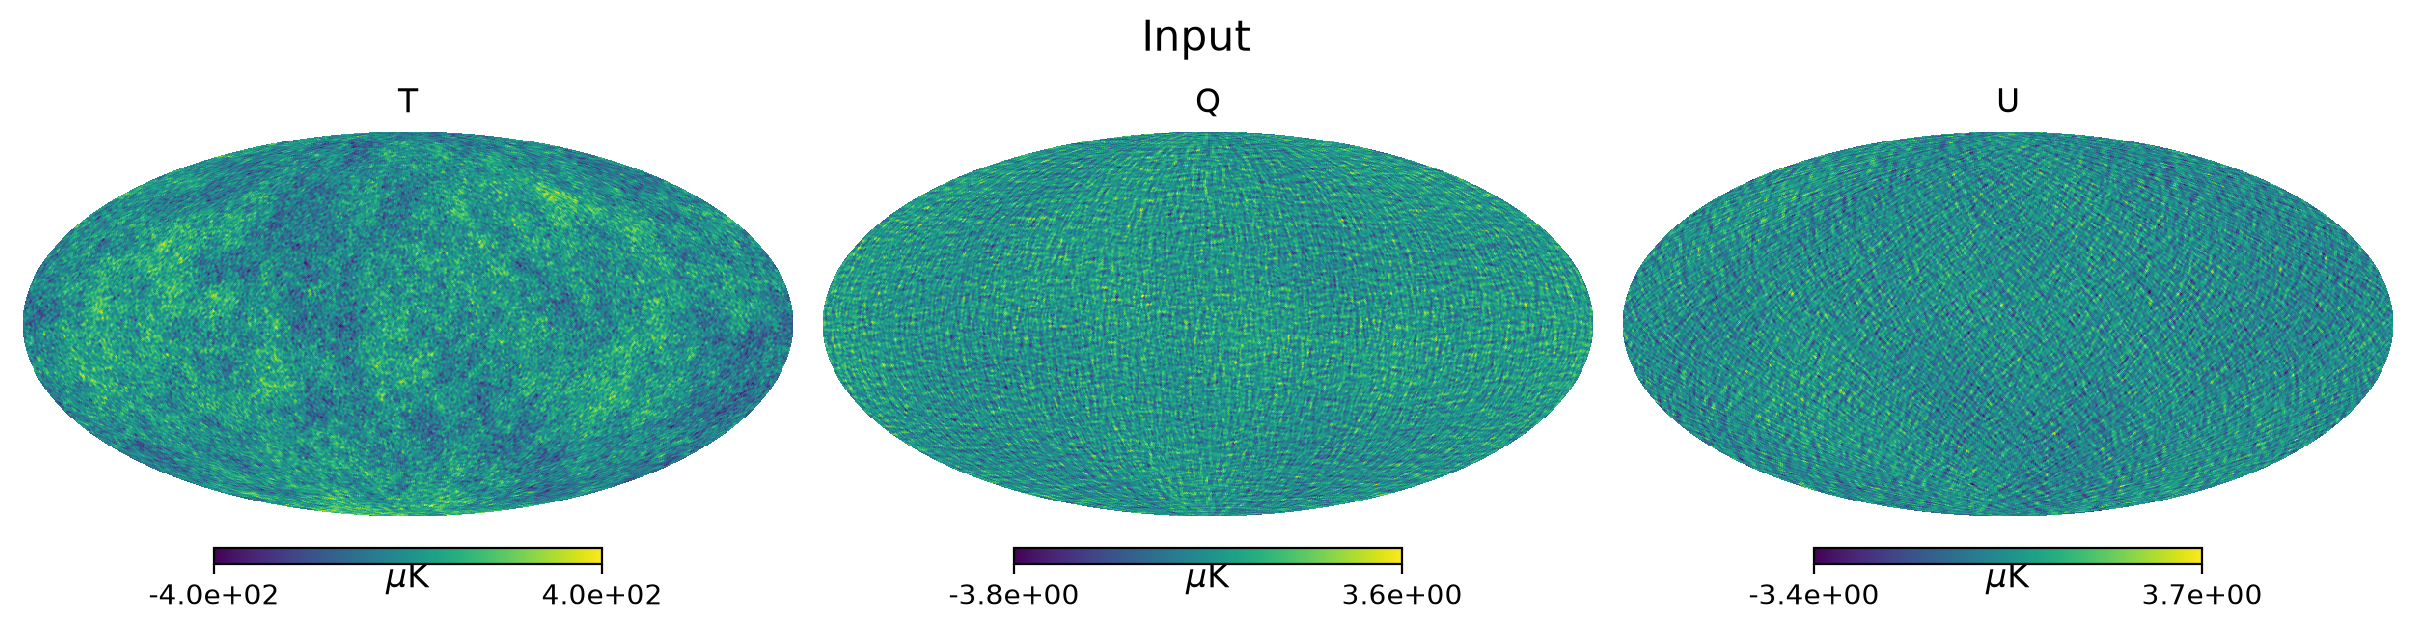

In [7]:
input_map = hp.alm2map(
    sky.alms_dict[det_planck_data.detector_names[0]], nside=nside, pol=True
)
plt.figure(figsize=(12, 3), dpi=200)
for i, label in enumerate(["T", "Q", "U"]):
    hp.mollview(
        input_map[i],
        sub=(1, 3, i + 1),
        title=f"{label}",
        unit=r"$\mu$K",
        cmap="viridis",
        format="%.1e",
        cbar=True,
        fontsize={"": 00},
    )
plt.suptitle("Input", fontsize=15)
plt.show()


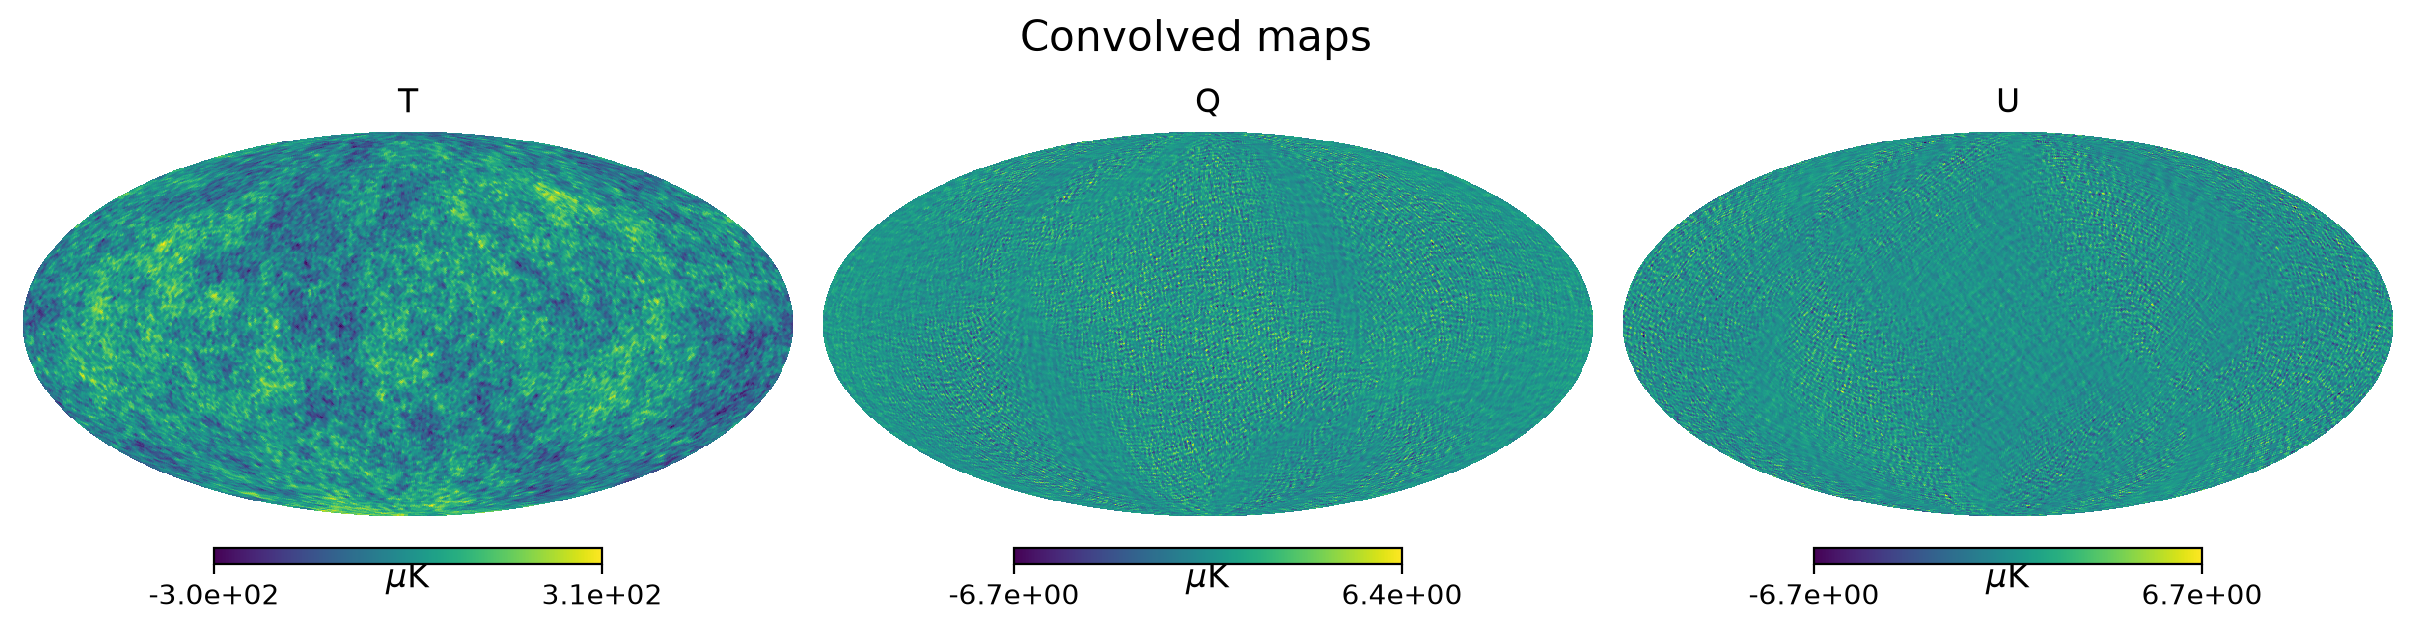

In [8]:
plt.figure(figsize=(12, 3), dpi=200)
for j, label2 in enumerate(["T", "Q", "U"]):
    hp.mollview(
        TQU_conv[j],
        sub=(1, 3, j + 1),
        title=f"{label2}",
        unit=r"$\mu$K",
        cmap="viridis",
        format="%.1e",
        cbar=True,
        fontsize={"": 00},
    )
plt.suptitle("Convolved maps", fontsize=15)
plt.show()


In [9]:
spect_conv = hp.anafast(TQU_conv, lmax=lmax)
spect_input = hp.alm2cl(sky.alms_dict[det_planck_data.detector_names[0]])


In [10]:
hp.alm2cl(sky.alms_dict[det_planck_data.detector_names[0]])


array([[ 0.00000000e+00,  0.00000000e+00,  9.44096849e+02, ...,
         5.33129784e-01,  5.55061602e-01,  4.93698597e-01],
       [ 0.00000000e+00,  0.00000000e+00,  4.07276152e-02, ...,
         2.70777804e-04,  2.55501014e-04,  2.94746998e-04],
       [ 0.00000000e+00,  0.00000000e+00,  1.33489263e-06, ...,
         2.26649908e-06,  2.26694931e-06,  2.15877487e-06],
       [ 0.00000000e+00,  0.00000000e+00,  4.63577483e+00, ...,
         7.19694509e-03,  6.95888851e-03,  7.35377917e-03],
       [ 0.00000000e+00,  0.00000000e+00,  1.23192297e-04, ...,
         8.87879447e-07, -7.87654112e-07, -1.76116497e-07],
       [ 0.00000000e+00,  0.00000000e+00,  1.55257193e-02, ...,
        -2.43291894e-05,  6.11339758e-06, -3.30702594e-05]],
      shape=(6, 257))

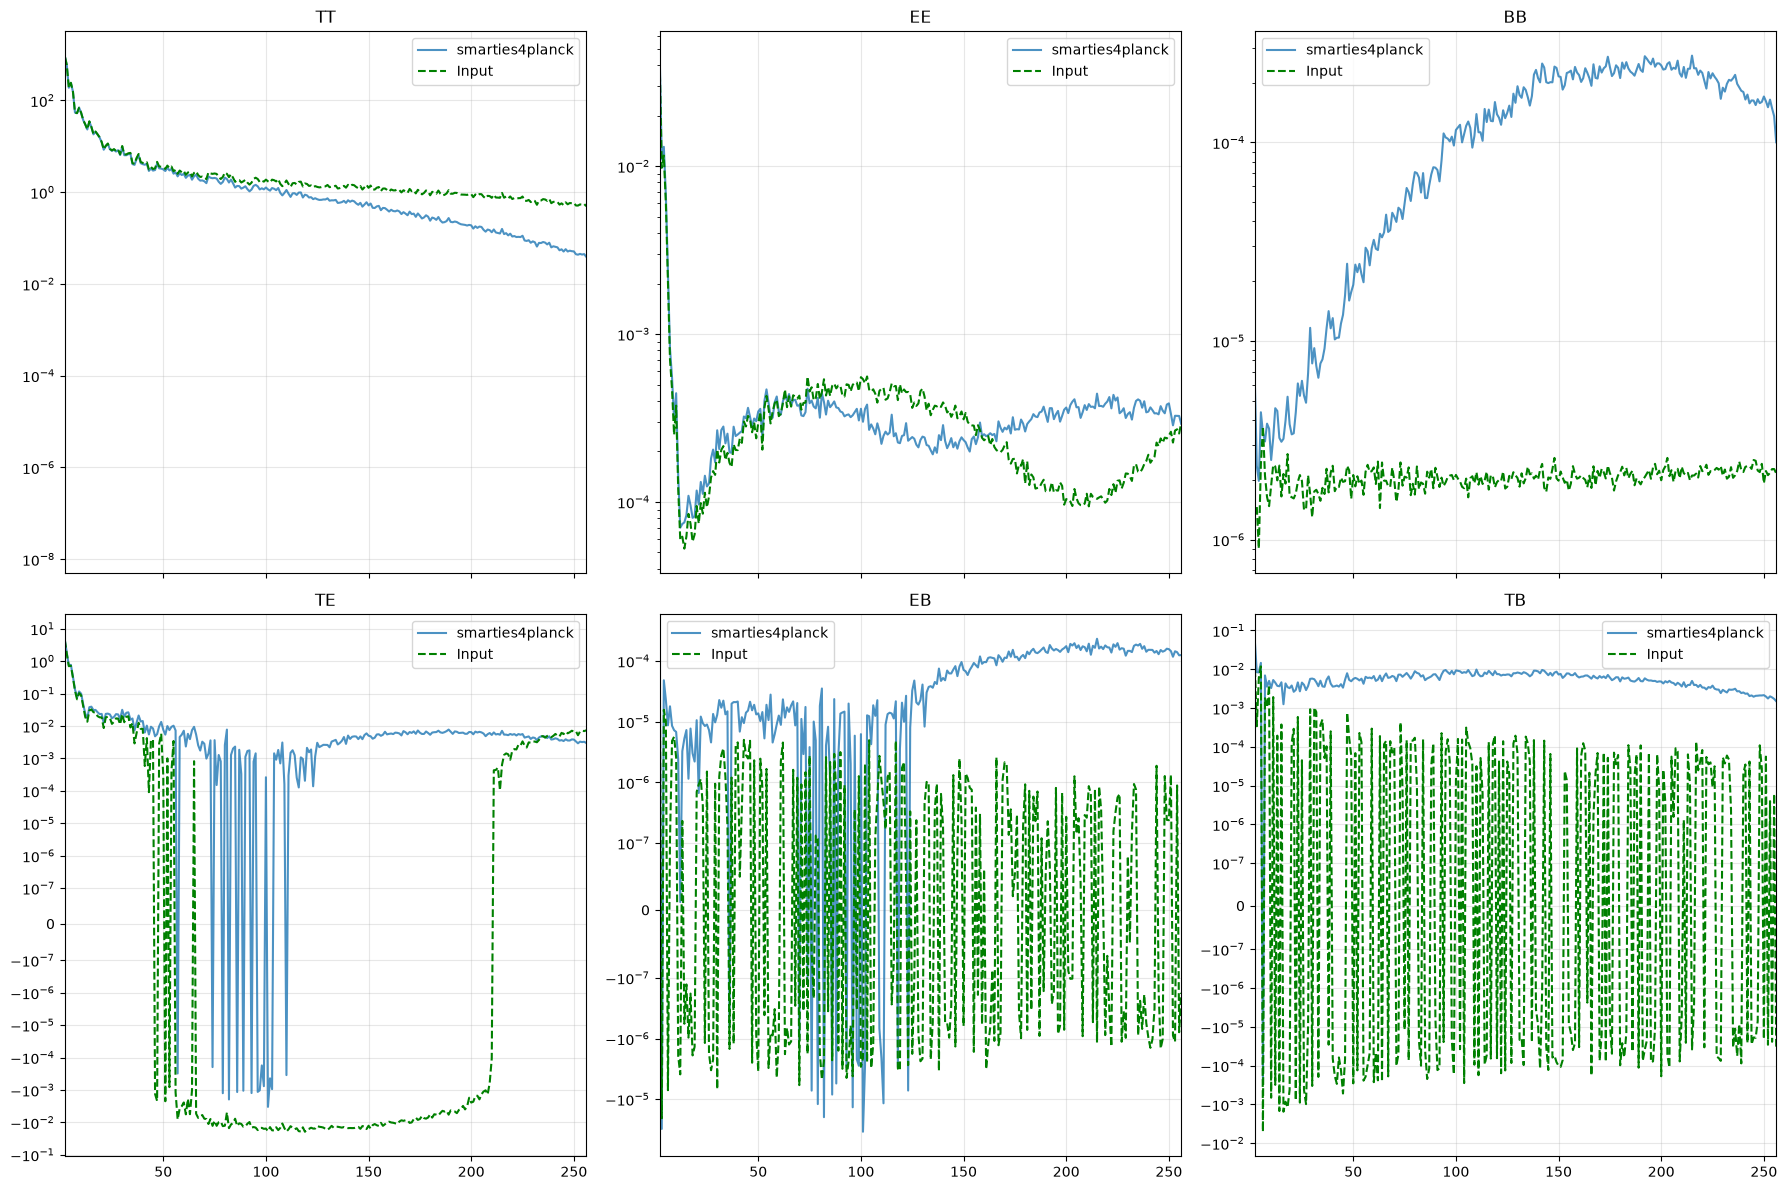

In [11]:
spec_order = [0, 1, 2, 3, 4, 5]
spec_labels = ["TT", "EE", "BB", "TE", "EB", "TB"]
ells = np.arange(lmax + 1)
fig, axes = plt.subplots(2, 3, figsize=(18, 12), sharex=True)
axes = axes.ravel()

for ax, idx, cur_label in zip(axes, spec_order, spec_labels):
    ax.plot(ells, spect_conv[idx], label="smarties4planck", alpha=0.8)

    ax.plot(
        ells,
        spect_input[idx][: lmax + 1],
        "--",
        color="green",
        label="Input",
    )
    qp_label = "TT" if cur_label in ["TT", "TE", "TB"] else cur_label
    ax.set_title(cur_label)
    if cur_label in ["TE", "TB", "EB"]:
        ax.set_yscale("symlog", linthresh=1e-7)
    else:
        ax.set_yscale("log")
    ax.set_xlim(2, lmax)
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
plt.show()
